In [1]:
#KIRUTHIKASHREE A

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
DS = sns.load_dataset('tips')

In [5]:
DS.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [6]:
DS.tail()

,total_bill,tip,sex,smoker,day,time,size
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2
243,18.78,3.00,Female,No,Thur,Dinner,2


In [7]:
DS.shape

(244, 7)

In [8]:
DS.size

1708

In [9]:
DS.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='str')

In [10]:
DS.dtypes

total_bill     float64
tip            float64
sex           category
smoker        category
day           category
time          category
size             int64
dtype: object

In [11]:
DS.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [14]:
DS.duplicated().sum()

np.int64(0)

In [16]:
DS['total_bill'] = DS['total_bill'].fillna(DS['total_bill'].mean())

In [17]:
DS['tip'] = DS['tip'].fillna(DS['tip'].mean())

In [18]:
DS.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [19]:
num_cols = DS.select_dtypes(include=np.number).columns

In [20]:
category_cols = DS.select_dtypes(include='category').columns

print("Numerical Columns:", num_cols)
print("Categorical Columns:", category_cols)

Numerical Columns: Index(['total_bill', 'tip', 'size'], dtype='str')
Categorical Columns: Index(['sex', 'smoker', 'day', 'time'], dtype='str')


In [23]:
#handle categorical missing values
for col in category_cols:
    DS[col] = DS[col].fillna(DS[col].mode()[0])

In [24]:
DS.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [25]:
#Encoding onehot

DS_encoded = pd.get_dummies(DS, columns=category_cols, dtype=int)

DS_encoded.head()

,total_bill,tip,size,sex_Male,sex_Female,smoker_Yes,smoker_No,day_Thur,day_Fri,day_Sat,day_Sun,time_Lunch,time_Dinner
0,16.99,1.01,2,0,1,0,1,0,0,0,1,0,1
1,10.34,1.66,3,1,0,0,1,0,0,0,1,0,1
2,21.01,3.50,3,1,0,0,1,0,0,0,1,0,1
3,23.68,3.31,2,1,0,0,1,0,0,0,1,0,1
4,24.59,3.61,4,0,1,0,1,0,0,0,1,0,1


In [28]:
from sklearn.preprocessing import LabelEncoder

label= LabelEncoder()

In [29]:
for col in category_cols:
    DS[col] = label.fit_transform(DS[col].astype(str))

In [30]:
DS.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,0,0,2,0,2
1,10.34,1.66,1,0,2,0,3
2,21.01,3.50,1,0,2,0,3
3,23.68,3.31,1,0,2,0,2
4,24.59,3.61,0,0,2,0,4


In [32]:
#Uni variant

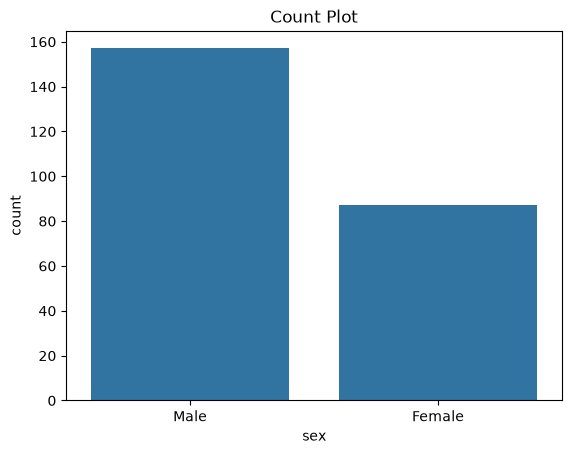

In [44]:
#Count plot 

sns.countplot(x='sex', data=DS)
plt.title('Count Plot')
plt.show()

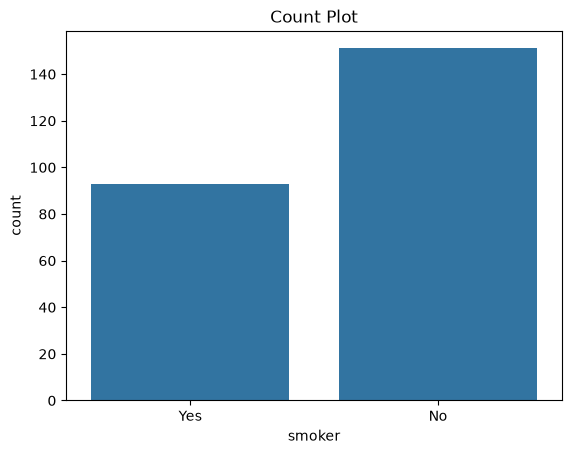

In [35]:
sns.countplot(x='smoker', data=DS)
plt.title('Count Plot')
plt.show()

In [48]:
#common 
DS['day'].mode()[0]


'Sat'

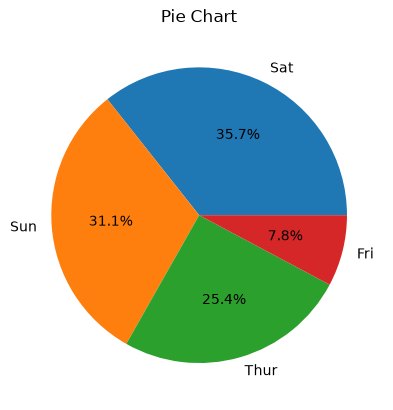

In [45]:
#pie chart

DS['day'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Pie Chart')
plt.ylabel('')
plt.show()

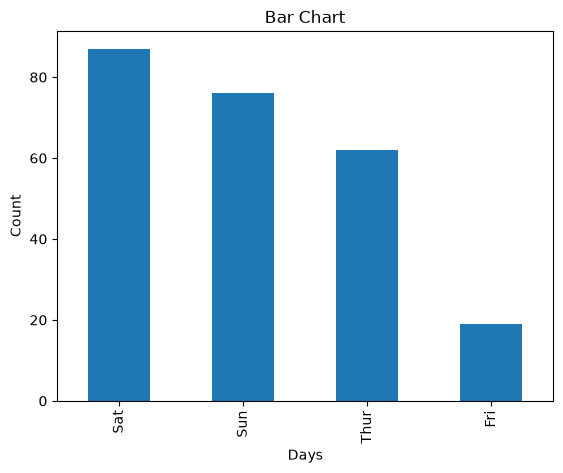

In [46]:
#Bar chart

DS['day'].value_counts().plot(kind='bar')

plt.title('Bar Chart')
plt.xlabel('Days')
plt.ylabel('Count')
plt.show()